# HIV-1 *pol* subtyping — fragment-length stress-test

Same three models as the per-class run — **LinearSVM** (TF-IDF 6-mer), **ResNet-18**
(TF-IDF 6-mer), **VGG-16** (raw 6-mer) — but each is **trained and tested on random
sequence windows** of decreasing length. The point: full-length *pol* is near-solved
by everything, so we shorten the input until models break, to see **which one degrades
most gracefully**.

- Split: the same leakage-free, cluster-grouped `StratifiedGroupKFold` (per seed).
- Fragmentation: one random contiguous window per sequence at each target length;
  encoders are **re-fit on the fragmented training set** each time (no leakage).
- Lengths: 300, 400, 500, 1000 bp, and full-length.

**Outputs** (`/kaggle/working/`): `fragment_results_raw.csv`, `fragment_results_summary.csv`
(mean ± std per model × length), and `degradation_curve.png` (macro-F1 vs length).

> **Compute:** with `SEEDS=[0]` and 5 lengths ≈ 3–4 h on one T4 (fits a session). Bump to
> `SEEDS=[0,1,2]` for error bars once the curve's shape looks right — that triples it, so
> split across sessions. Accelerator: **GPU T4 ×2**, commit with *Save & Run All*.

### 1. Imports

In [1]:
import warnings; warnings.filterwarnings("ignore")
import os, glob, random
import numpy as np, pandas as pd, tensorflow as tf
import matplotlib.pyplot as plt
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.svm import LinearSVC
from sklearn.utils.class_weight import compute_class_weight
from sklearn.metrics import f1_score, matthews_corrcoef, balanced_accuracy_score, accuracy_score
from tensorflow.keras.layers import (Input, Conv1D, BatchNormalization, ReLU, Add,
    GlobalAveragePooling1D, Dropout, Dense, MaxPooling1D, GaussianNoise, SpatialDropout1D, Layer)
from tensorflow.keras.models import Model
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import CategoricalCrossentropy
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.utils import to_categorical
print("TF", tf.__version__, "| GPUs:", len(tf.config.list_physical_devices("GPU")))

TF 2.20.0 | GPUs: 2


### 2. Config

In [2]:
SEEDS   = [0]                         # start with 1 seed; use [0,1,2] for error bars later
LENGTHS = [300, 400, 500, 1000, None] # None = full length; bp windows otherwise
EPOCHS  = 120
BATCH   = 48
OUT     = "/kaggle/working"
os.makedirs(OUT, exist_ok=True)

### 3. Load data (clean 10-class set)

In [3]:
df = pd.read_csv("/kaggle/input/datasets/yashrajrajarishi/subtype-classification/prepared_sequences_clean.csv")

le = LabelEncoder(); y_all = le.fit_transform(df["subtype"].values)
CLASSES = list(le.classes_); n_cls = len(CLASSES)
X_all = df["sequence"].values; grp_all = df["cluster"].values
print(f"{len(df)} seqs | {n_cls} classes: {CLASSES}")

24072 seqs | 10 classes: ['01_AE', '02_AG', '07_BC', '08_BC', 'A1', 'A6', 'B', 'C', 'D', 'G']


### 4. Helpers: split, fragment, encoders, metrics

In [4]:
# --- leakage-free split (depends on seed only; we fragment the resulting splits) ---
def grouped_split(X, y, grp, seed):
    s1 = StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=seed)
    trv, te = next(s1.split(X, y, grp))
    s2 = StratifiedGroupKFold(n_splits=4, shuffle=True, random_state=seed)
    tr_rel, va_rel = next(s2.split(X[trv], y[trv], grp[trv]))
    return trv[tr_rel], trv[va_rel], te

# --- fragmentation: one random contiguous window of length L per sequence ---
def fragment(seqs, L, rng):
    if L is None: return list(seqs)                      # full length, untouched
    out = []
    for s in seqs:
        if len(s) <= L: out.append(s)                    # already shorter -> keep whole
        else:
            st = int(rng.integers(0, len(s) - L + 1))
            out.append(s[st:st+L])
    return out

# --- encoders, RE-FIT on the fragmented training set each time ---
def kmers(seq, k=6): return [seq[i:i+k] for i in range(len(seq)-k+1)]

def make_tfidf(train, k=6, max_features=512):
    vec = TfidfVectorizer(max_features=max_features)
    vec.fit([" ".join(kmers(s,k)) for s in train])
    return lambda seqs: vec.transform([" ".join(kmers(s,k)) for s in seqs]).toarray().astype(np.float32)

def make_kfreq(train, k=6):
    vocab = sorted({km for s in train for km in kmers(s,k)}); idx = {kk:i for i,kk in enumerate(vocab)}
    def enc(seqs):
        out = np.zeros((len(seqs), len(vocab)), np.float32)
        for i, s in enumerate(seqs):
            for km in kmers(s,k):
                if km in idx: out[i, idx[km]] += 1
            t = out[i].sum()
            if t: out[i] /= t
        return out
    return enc

def score(y_true, y_pred):
    return dict(f1=round(f1_score(y_true, y_pred, average="macro"),4),
                mcc=round(matthews_corrcoef(y_true, y_pred),4),
                bal_acc=round(balanced_accuracy_score(y_true, y_pred),4),
                acc=round(accuracy_score(y_true, y_pred),4))

### 5. ResNet-18 and VGG-16 (1D) + a train helper

In [5]:
class StochasticDepth(Layer):
    def __init__(self, p=0.85, **kw): super().__init__(**kw); self.p = p
    def call(self, x, training=None):
        if not training: return x
        r = tf.random.uniform([tf.shape(x)[0],1,1]); return x*tf.floor(self.p+r)/self.p
    def get_config(self): return {**super().get_config(), "p": self.p}

def res_block(x, f, stride=1, sp=0.85, dr=0.1):
    sc = x
    x = Conv1D(f,3,strides=stride,padding="same",use_bias=False)(x)
    x = ReLU()(BatchNormalization()(x)); x = SpatialDropout1D(dr)(x)
    x = BatchNormalization()(Conv1D(f,3,padding="same",use_bias=False)(x))
    if stride!=1 or sc.shape[-1]!=f:
        sc = BatchNormalization()(Conv1D(f,1,strides=stride,padding="same",use_bias=False)(sc))
    return ReLU()(Add()([StochasticDepth(sp)(x), sc]))

def build_resnet18(L, n):
    inp = Input((L,1)); x = GaussianNoise(0.05)(inp)
    x = ReLU()(BatchNormalization()(Conv1D(32,7,strides=2,padding="same",use_bias=False)(x)))
    x = MaxPooling1D(3,strides=2,padding="same")(x)
    for ff,sp in [(32,.95),(32,.92)]:   x = res_block(x,ff,1,sp)
    for ff,sp in [(64,.88),(64,.85)]:   x = res_block(x,ff,2 if ff!=x.shape[-1] else 1,sp)
    for ff,sp in [(128,.80),(128,.78)]: x = res_block(x,ff,2 if ff!=x.shape[-1] else 1,sp)
    for ff,sp in [(256,.75),(256,.72)]: x = res_block(x,ff,2 if ff!=x.shape[-1] else 1,sp)
    x = Dropout(0.4)(GlobalAveragePooling1D()(x))
    m = Model(inp, Dense(n,activation="softmax")(x))
    m.compile(optimizer=Adam(3e-4), loss=CategoricalCrossentropy(label_smoothing=0.1), metrics=["accuracy"])
    return m

def build_vgg16(L, n):
    def cb(x,f,k):
        for _ in range(k): x = ReLU()(BatchNormalization()(Conv1D(f,3,padding="same",use_bias=False)(x)))
        return MaxPooling1D(2,padding="same")(x)
    inp = Input((L,1))
    x = cb(inp,32,2); x = cb(x,64,2); x = cb(x,128,3); x = cb(x,256,3); x = cb(x,256,3)
    x = Dropout(0.4)(GlobalAveragePooling1D()(x)); x = Dropout(0.4)(ReLU()(Dense(256)(x)))
    m = Model(inp, Dense(n,activation="softmax")(x))
    m.compile(optimizer=Adam(3e-4), loss=CategoricalCrossentropy(label_smoothing=0.1), metrics=["accuracy"])
    return m

def train_cnn(build_fn, ftr, fva, fte, ytr, yva, cw):
    sc = StandardScaler()
    a = sc.fit_transform(ftr)[...,None]; b = sc.transform(fva)[...,None]; c = sc.transform(fte)[...,None]
    tf.keras.backend.clear_session()
    m = build_fn(a.shape[1], n_cls)
    m.fit(a, to_categorical(ytr,n_cls), validation_data=(b,to_categorical(yva,n_cls)),
          epochs=EPOCHS, batch_size=BATCH, class_weight=cw, shuffle=True, verbose=0,
          callbacks=[EarlyStopping("val_loss",patience=15,restore_best_weights=True),
                     ReduceLROnPlateau("val_loss",factor=0.5,patience=6,min_lr=1e-6)])
    return m.predict(c, verbose=0).argmax(1)

### 6. Main loop — for each seed, split once, then sweep fragment lengths

In [6]:
rows = []
for seed in SEEDS:
    random.seed(seed); np.random.seed(seed); tf.random.set_seed(seed)
    tr, va, te = grouped_split(X_all, y_all, grp_all, seed)
    ytr, yva, yte = y_all[tr], y_all[va], y_all[te]
    cw = dict(enumerate(compute_class_weight("balanced", classes=np.unique(ytr), y=ytr)))

    for L in LENGTHS:
        rng = np.random.default_rng(seed*100 + (L or 9999))          # deterministic fragmentation
        Ftr = fragment(X_all[tr], L, rng)
        Fva = fragment(X_all[va], L, rng)
        Fte = fragment(X_all[te], L, rng)
        label = "full" if L is None else str(L)

        # encoders re-fit on the FRAGMENTED training set (no leakage)
        tfidf = make_tfidf(Ftr); kfreq = make_kfreq(Ftr)
        Ttr, Tva, Tte = tfidf(Ftr), tfidf(Fva), tfidf(Fte)           # TF-IDF -> SVM, ResNet
        Ktr, Kva, Kte = kfreq(Ftr), kfreq(Fva), kfreq(Fte)           # raw 6-mer -> VGG

        # 1) LinearSVM baseline
        svm = LinearSVC(class_weight="balanced"); svm.fit(Ttr, ytr)
        rows.append({"model":"linearsvm","length":label,"length_num":(L or 3000),"seed":seed,
                     **score(yte, svm.predict(Tte))})
        # 2) ResNet-18 on TF-IDF
        p = train_cnn(build_resnet18, Ttr, Tva, Tte, ytr, yva, cw)
        rows.append({"model":"resnet18","length":label,"length_num":(L or 3000),"seed":seed, **score(yte,p)})
        # 3) VGG-16 on raw 6-mer
        p = train_cnn(build_vgg16, Ktr, Kva, Kte, ytr, yva, cw)
        rows.append({"model":"vgg16","length":label,"length_num":(L or 3000),"seed":seed, **score(yte,p)})

        r = rows[-3:]
        print(f"[seed {seed}] L={label:>4}  " + "  ".join(f"{x['model']}=F1 {x['f1']}" for x in r))

I0000 00:00:1783846098.721732      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13756 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1783846098.724600      22 gpu_device.cc:2020] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13756 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5
I0000 00:00:1783846124.739803      71 device_compiler.h:196] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


[seed 0] L= 300  linearsvm=F1 0.8424  resnet18=F1 0.8048  vgg16=F1 0.7662
[seed 0] L= 400  linearsvm=F1 0.9019  resnet18=F1 0.8579  vgg16=F1 0.8052
[seed 0] L= 500  linearsvm=F1 0.9506  resnet18=F1 0.9066  vgg16=F1 0.8688
[seed 0] L=1000  linearsvm=F1 0.9837  resnet18=F1 0.9577  vgg16=F1 0.9614
[seed 0] L=full  linearsvm=F1 0.9913  resnet18=F1 0.9936  vgg16=F1 0.9952


### 7. Aggregate, save, and plot the degradation curve

    model length  length_num  f1_mean  f1_std  mcc_mean  mcc_std  bal_acc_mean  bal_acc_std  acc_mean  acc_std
linearsvm    300         300   0.8424     NaN    0.9261      NaN        0.8667          NaN    0.9507      NaN
linearsvm    400         400   0.9019     NaN    0.9586      NaN        0.9022          NaN    0.9726      NaN
linearsvm    500         500   0.9506     NaN    0.9787      NaN        0.9480          NaN    0.9860      NaN
linearsvm   1000        1000   0.9837     NaN    0.9917      NaN        0.9835          NaN    0.9945      NaN
linearsvm   full        3000   0.9913     NaN    0.9960      NaN        0.9864          NaN    0.9974      NaN
 resnet18    300         300   0.8048     NaN    0.9178      NaN        0.8162          NaN    0.9454      NaN
 resnet18    400         400   0.8579     NaN    0.9400      NaN        0.8623          NaN    0.9601      NaN
 resnet18    500         500   0.9066     NaN    0.9665      NaN        0.8963          NaN    0.9779      NaN
 

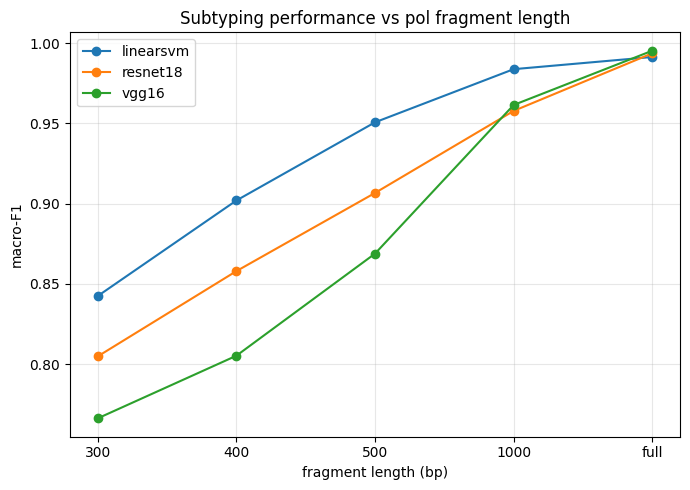


Saved: fragment_results_raw.csv, fragment_results_summary.csv, degradation_curve.png


In [7]:
raw = pd.DataFrame(rows)
raw.to_csv(f"{OUT}/fragment_results_raw.csv", index=False)

summ = (raw.groupby(["model","length","length_num"])[["f1","mcc","bal_acc","acc"]]
           .agg(["mean","std"]).round(4))
summ.columns = [f"{m}_{s}" for m,s in summ.columns]
summ = summ.reset_index().sort_values(["model","length_num"])
summ.to_csv(f"{OUT}/fragment_results_summary.csv", index=False)
print(summ.to_string(index=False))

# --- degradation curve: macro-F1 vs fragment length, one line per model ---
plt.figure(figsize=(7,5))
order = ["300","400","500","1000","full"]
for model in ["linearsvm","resnet18","vgg16"]:
    d = summ[summ.model==model].set_index("length").reindex(order).reset_index()
    plt.plot(order, d["f1_mean"], marker="o", label=model)
    if d["f1_std"].notna().any():
        plt.fill_between(order, d["f1_mean"]-d["f1_std"], d["f1_mean"]+d["f1_std"], alpha=0.15)
plt.xlabel("fragment length (bp)"); plt.ylabel("macro-F1")
plt.title("Subtyping performance vs pol fragment length")
plt.legend(); plt.grid(alpha=0.3); plt.tight_layout()
plt.savefig(f"{OUT}/degradation_curve.png", dpi=150)
plt.show()
print("\nSaved: fragment_results_raw.csv, fragment_results_summary.csv, degradation_curve.png")